# Explainable AI — SHAP Analysis

Use SHAP to understand which words drive the XGBoost model's predictions.

In [2]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import joblib
import shap
import matplotlib.pyplot as plt

from config import TEST_CSV, MODELS_DIR

# Load test data, model, and vectorizer
test = pd.read_csv(TEST_CSV)
test["review_heavy"] = test["review_heavy"].fillna("")

xgb_model = joblib.load(MODELS_DIR / "xgboost_sentiment.joblib")
tfidf_vec = joblib.load(MODELS_DIR / "tfidf_vectorizer.joblib")

X_test_tfidf = tfidf_vec.transform(test["review_heavy"])
feature_names = tfidf_vec.get_feature_names_out()

print(f"Loaded model and vectorizer")
print(f"Test set: {X_test_tfidf.shape}")

Loaded model and vectorizer
Test set: (1335, 5000)


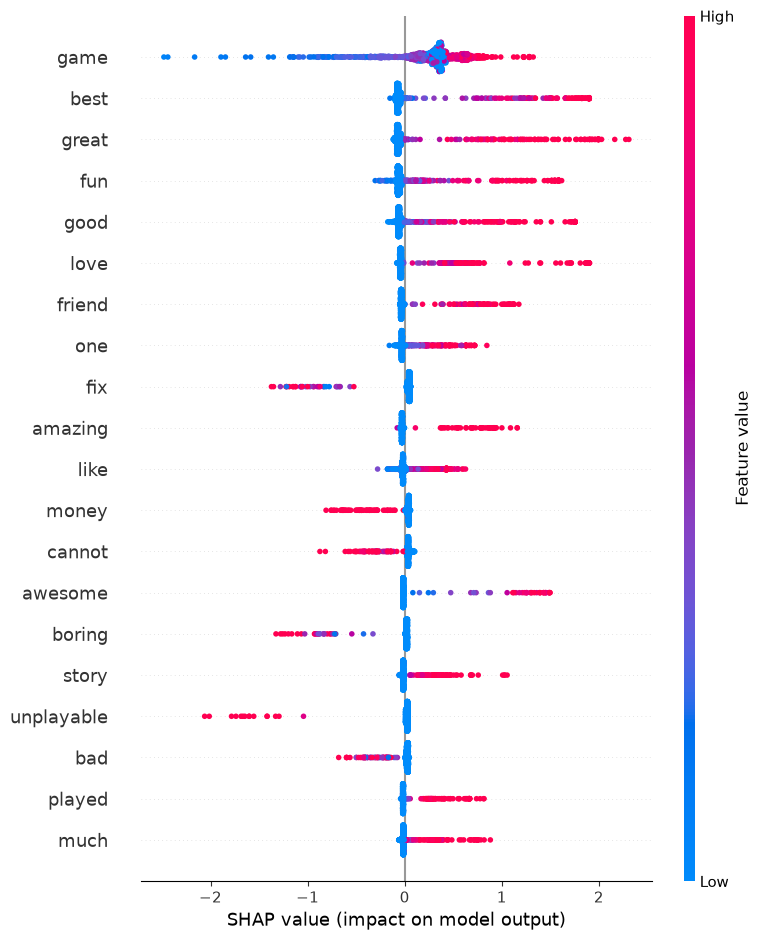

In [4]:
# SHAP TreeExplainer — works natively with XGBoost
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_tfidf)

# Convert sparse to dense for colored plot
X_test_dense = X_test_tfidf.toarray()

# Global summary — which features matter most across all predictions
shap.summary_plot(shap_values, X_test_dense, feature_names=feature_names, max_display=20)

Review: 'bought island wth thinking'
True label: Not Recommended
Predicted: Recommended


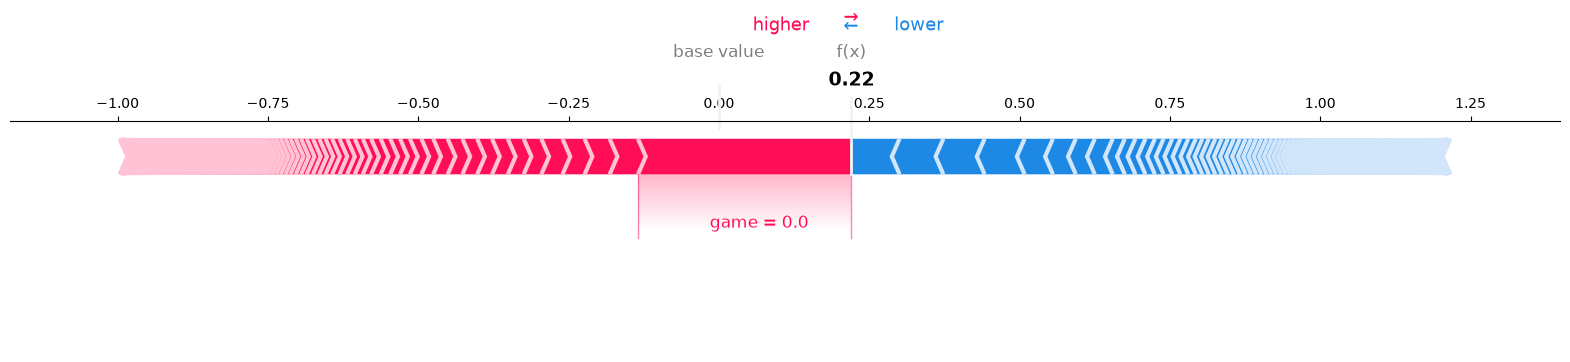

In [5]:
# Local explanation — explain a single prediction
idx = 0  # first test review
print(f"Review: '{test['review_heavy'].iloc[idx]}'")
print(f"True label: {test['recommendation'].iloc[idx]}")
print(f"Predicted: {'Recommended' if xgb_model.predict(X_test_tfidf[idx])[0] == 1 else 'Not Recommended'}")

shap.force_plot(explainer.expected_value, shap_values[idx], X_test_dense[idx], 
                feature_names=feature_names, matplotlib=True)

## SHAP Summary

- **Global:** Positive words (best, great, fun, love, amazing) push toward Recommended;
  negative words (fix, money, cannot) push toward Not Recommended
- **Local:** Short/ambiguous reviews with no strong signal are prone to misclassification
- This highlights the limitation of bag-of-words models on short reviews — 
  a contextual model like DistilBERT can better handle these cases